# K-Nearest Neighbours (KNN)
## Human Activity Recognition from Wearable Sensors

**Dataset:** `har_wearable_data.csv` — wristband sensor data from 10 participants doing 6 activities.

### Learning goals
1. Understand how k controls the bias-variance trade-off — choose k with cross-validation
2. See concretely how unscaled features break distance-based models — fix with StandardScaler
3. Compare KNN's performance and inference cost against Random Forest on the same task

---

## Step 1 — Setup & Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import time
plt.rcParams['figure.figsize']=(10,4)
sns.set_theme(style='whitegrid')

df = pd.read_csv('har_wearable_data.csv')
sensor_cols = ['acc_x','acc_y','acc_z','gyro_x','gyro_y','gyro_z','heart_rate_bpm','skin_temp_c']
df[sensor_cols] = df[sensor_cols].fillna(df[sensor_cols].median())
df['acc_magnitude']  = np.sqrt(df['acc_x']**2+df['acc_y']**2+df['acc_z']**2)
df['gyro_magnitude'] = np.sqrt(df['gyro_x']**2+df['gyro_y']**2+df['gyro_z']**2)
FEATURES = sensor_cols + ['acc_magnitude','gyro_magnitude']
print(df['activity'].value_counts())

activity
Sitting     350
Standing    350
Walking     350
Running     350
Stairs      350
Cycling     350
Name: count, dtype: int64


## Step 2 — Why Normalisation Matters for KNN

KNN uses **Euclidean distance**. A feature measured in hundreds (CO₂ ppm) will dominate
one measured in ones (gyro rad/s). We must scale before using KNN.

In [3]:
X = df[FEATURES]; y = df['activity']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

# Without scaling
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
acc_raw = knn_raw.score(X_test, y_test)

# With scaling
sc = StandardScaler()
X_tr_sc = sc.fit_transform(X_train)
X_te_sc = sc.transform(X_test)
knn_sc = KNeighborsClassifier(n_neighbors=5)
knn_sc.fit(X_tr_sc, y_train)
acc_sc = knn_sc.score(X_te_sc, y_test)

print(f'Accuracy WITHOUT scaling: {acc_raw:.3f}')
print(f'Accuracy WITH scaling:    {acc_sc:.3f}')
print(f'Improvement:              +{acc_sc-acc_raw:.3f}')

Accuracy WITHOUT scaling: 0.593
Accuracy WITH scaling:    0.619
Improvement:              +0.026


## Step 3 — Choosing k with Cross-Validation

Small k = memorises noise (overfit). Large k = too smooth (underfit). We sweep k and pick the best.

Best k = 5  (CV accuracy = 0.579)


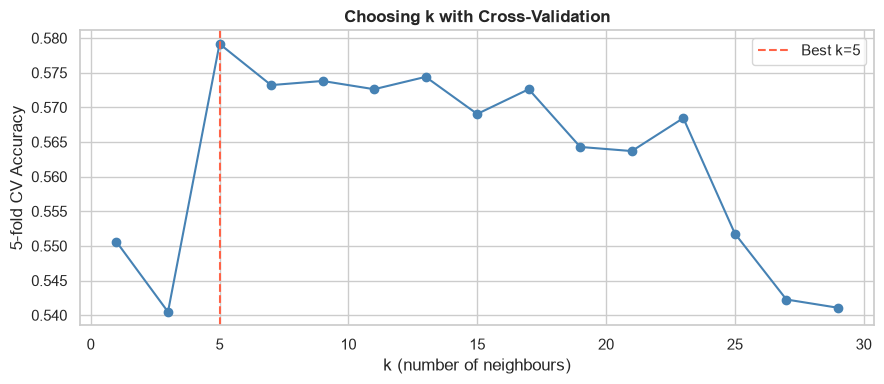

In [4]:
k_values = list(range(1,31,2))
cv_scores = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    cv_scores.append(cross_val_score(knn, X_tr_sc, y_train, cv=5).mean())

best_k = k_values[np.argmax(cv_scores)]
print(f'Best k = {best_k}  (CV accuracy = {max(cv_scores):.3f})')

plt.figure(figsize=(9,4))
plt.plot(k_values, cv_scores, 'o-', color='steelblue')
plt.axvline(best_k, color='tomato', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('k (number of neighbours)'); plt.ylabel('5-fold CV Accuracy')
plt.title('Choosing k with Cross-Validation', fontweight='bold'); plt.legend()
plt.tight_layout(); plt.show()

## Step 4 — Train with Best k & Evaluate

In [5]:
knn_best = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_best.fit(X_tr_sc, y_train)
y_pred = knn_best.predict(X_te_sc)

print(f'Test Accuracy: {knn_best.score(X_te_sc,y_test):.3f}')
print()
print(classification_report(y_test, y_pred))

Test Accuracy: 0.619

              precision    recall  f1-score   support

     Cycling       0.50      0.74      0.60        70
     Running       0.92      0.63      0.75        70
     Sitting       0.55      0.70      0.62        70
      Stairs       0.54      0.39      0.45        70
    Standing       0.55      0.46      0.50        70
     Walking       0.79      0.80      0.79        70

    accuracy                           0.62       420
   macro avg       0.64      0.62      0.62       420
weighted avg       0.64      0.62      0.62       420



## Step 5 — Confusion Matrix

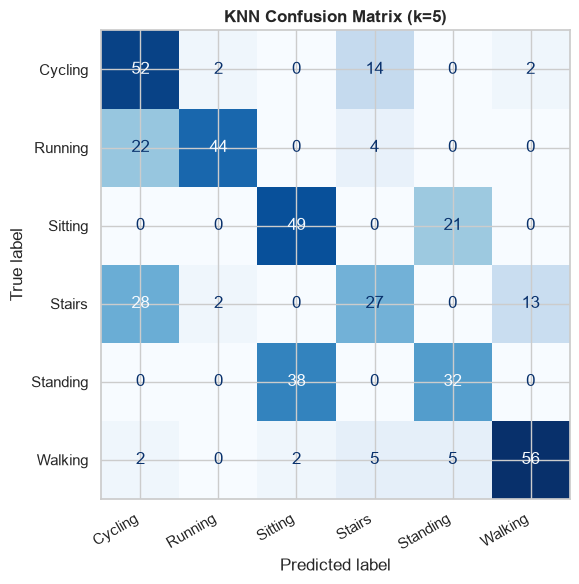

Which activities are confused most? Do they make physical sense?


In [6]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8,6))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues', ax=plt.gca(), colorbar=False)
plt.title(f'KNN Confusion Matrix (k={best_k})', fontweight='bold')
plt.xticks(rotation=30,ha='right'); plt.tight_layout(); plt.show()

print('Which activities are confused most? Do they make physical sense?')

## Step 6 — KNN vs Random Forest: Accuracy & Speed

In [7]:
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)   # RF needs NO scaling
rf_acc = rf.score(X_test, y_test)

# Time a single prediction
sample = X_te_sc[:1]
t0 = time.perf_counter()
for _ in range(1000): knn_best.predict(sample)
knn_time = (time.perf_counter()-t0)/1000 * 1e6

sample_raw = X_test.iloc[:1]
t0 = time.perf_counter()
for _ in range(1000): rf.predict(sample_raw)
rf_time = (time.perf_counter()-t0)/1000 * 1e6

print(f"{'Model':<16} {'Accuracy':>10} {'Inference (µs)':>16}")
print('-'*45)
print(f"{'KNN (k='+str(best_k)+')':16} {knn_best.score(X_te_sc,y_test):10.3f} {knn_time:16.1f}")
print(f"{'Random Forest':16} {rf_acc:10.3f} {rf_time:16.1f}")

print('\nKey insight: KNN stores ALL training data — slow at inference on large datasets.')
print('Random Forest stores only the tree structure — fast at inference.')

Model              Accuracy   Inference (µs)
---------------------------------------------
KNN (k=5)             0.619            369.5
Random Forest         0.733          13768.4

Key insight: KNN stores ALL training data — slow at inference on large datasets.
Random Forest stores only the tree structure — fast at inference.


---

**Try this:** Change `n_neighbors` to 1. What happens to training vs test accuracy?

**Try this:** Add `weights='distance'` to KNeighborsClassifier. Does accuracy improve?

**Deployment note:** KNN is not suitable for microcontrollers — it must store all training data.
Random Forest converts to a small C header file with `emlearn`.

